# Movie Recommender — Matrix Factorization (BPR)
CCAI 422 · University of Jeddah

Run: **Runtime ▸ Run all**.

### 1) Download MovieLens-1M

In [1]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-1m.zip -O ml-1m.zip
!unzip -o -q ml-1m.zip

✅ MovieLens-1M downloaded


### 2) Imports

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)

### 3) Load & preprocess data

In [3]:
def load_data(path="ml-1m/ratings.dat", max_users=1000, min_ratings=10, test_ratio=0.2):
    df = pd.read_csv(path, sep="::", engine="python",
                     names=["user_id", "movie_id", "rating", "timestamp"])
    df = df[df.rating >= 4]                                 # ratings >= 4 = a "like"
    df = df[df.user_id.isin(df.user_id.value_counts().index[:max_users])]
    while True:                                             # keep a 10-core
        uc, ic = df.user_id.value_counts(), df.movie_id.value_counts()
        d = df[df.user_id.isin(uc[uc >= min_ratings].index) &
               df.movie_id.isin(ic[ic >= min_ratings].index)]
        if len(d) == len(df):
            break
        df = d
    users = {u: k for k, u in enumerate(sorted(df.user_id.unique()))}
    items = {m: k for k, m in enumerate(sorted(df.movie_id.unique()))}
    df["u"], df["i"] = df.user_id.map(users), df.movie_id.map(items)
    nu, ni = len(users), len(items)
    train_pos, test_pos = {u: [] for u in range(nu)}, {u: [] for u in range(nu)}
    for u, g in df.groupby("u"):                            # 80/20 split per user
        m = g["i"].to_numpy(); rng.shuffle(m); cut = max(1, int(len(m) * test_ratio))
        test_pos[u], train_pos[u] = m[:cut], m[cut:]
    pairs = np.array([(u, i) for u in range(nu) for i in train_pos[u]])
    pop = np.zeros(ni)
    for u in range(nu):
        pop[train_pos[u]] += 1
    print(f"{nu} users, {ni} movies, {len(pairs)} train / {sum(len(v) for v in test_pos.values())} test")
    return dict(n_users=nu, n_items=ni, train_pos=train_pos, test_pos=test_pos, pairs=pairs, pop=pop)

data = load_data()

1000 users, 2497 movies, 223106 train / 55264 test


### 4) Matrix-Factorization model (BPR) + popularity baseline

In [4]:
class MF:
    def __init__(self, n_users, n_items, k=32, lr=0.05, reg=0.02):
        self.n_users, self.n_items, self.lr, self.reg = n_users, n_items, lr, reg
        self.P = rng.normal(0, 0.1, (n_users, k))          # user vectors
        self.Q = rng.normal(0, 0.1, (n_items, k))          # movie vectors

    def fit(self, data, epochs=30, batch=1024):
        pairs = data["pairs"]
        for ep in range(1, epochs + 1):
            for _ in range(max(1, len(pairs) // batch)):
                idx = rng.integers(0, len(pairs), batch)
                u, i = pairs[idx, 0], pairs[idx, 1]
                j = rng.integers(0, self.n_items, batch)
                x = np.sum(self.P[u] * (self.Q[i] - self.Q[j]), axis=1)
                g = (1 / (1 + np.exp(np.clip(x, -30, 30))))[:, None]
                np.add.at(self.P, u, self.lr * (g * (self.Q[i] - self.Q[j]) - self.reg * self.P[u]))
                np.add.at(self.Q, i, self.lr * (g * self.P[u] - self.reg * self.Q[i]))
                np.add.at(self.Q, j, self.lr * (-g * self.P[u] - self.reg * self.Q[j]))
            if ep % 10 == 0:
                print(f"  epoch {ep}/{epochs}")
        return self

    def scores_for(self, users):
        return self.P[users] @ self.Q.T

class Popularity:
    def __init__(self, pop): self.pop = pop
    def scores_for(self, users): return np.tile(self.pop, (len(users), 1))

### 5) Evaluation (Recall / NDCG / Precision @10)

In [5]:
def evaluate(model, data, K=10, on_train=False):
    target = data["train_pos"] if on_train else data["test_pos"]
    hide = {u: (np.array([], int) if on_train else data["train_pos"][u]) for u in range(data["n_users"])}
    users = [u for u in range(data["n_users"]) if len(target[u]) > 0]
    R, N, P = [], [], []
    idcg = np.cumsum(1 / np.log2(np.arange(2, K + 2)))
    sc = model.scores_for(np.array(users))
    for row, u in enumerate(users):
        s = sc[row].copy(); s[hide[u]] = -1e9
        top = np.argpartition(-s, K)[:K]; top = top[np.argsort(-s[top])]
        gt = set(target[u].tolist())
        hits = np.array([1.0 if it in gt else 0.0 for it in top])
        R.append(hits.sum() / len(gt)); P.append(hits.sum() / K)
        N.append(np.sum(hits / np.log2(np.arange(2, K + 2))) / idcg[min(len(gt), K) - 1])
    return {"Recall@10": float(np.mean(R)), "NDCG@10": float(np.mean(N)), "Precision@10": float(np.mean(P))}

### 6) Train & results

In [6]:
pop = Popularity(data["pop"])
mf0 = MF(data["n_users"], data["n_items"], reg=0.0).fit(data)     # no regularization (over-fits)
mfr = MF(data["n_users"], data["n_items"], reg=0.02).fit(data)    # + L2 regularization (ours)

models = {"Popularity": pop, "MF (no reg)": mf0, "MF + L2 (ours)": mfr}
rows = {name: evaluate(m, data) for name, m in models.items()}
print("\nTEST results (top-10):")
print(pd.DataFrame(rows).T.round(4))

  epoch 10/30
  epoch 20/30
  epoch 30/30
  epoch 10/30
  epoch 20/30
  epoch 30/30

TEST results (top-10):
                Recall@10  NDCG@10  Precision@10
Popularity         0.0611   0.3524        0.3229
MF (no reg)        0.0536   0.2928        0.2800
MF + L2 (ours)     0.0729   0.4031        0.3820


### 7) Charts

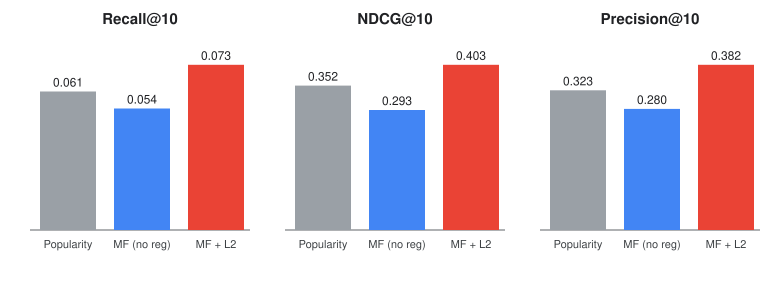

In [7]:
names, colors = list(models.keys()), ["#9aa0a6", "#4285f4", "#ea4335"]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a, metric in zip(ax, ["Recall@10", "NDCG@10", "Precision@10"]):
    vals = [rows[n][metric] for n in names]
    a.bar(names, vals, color=colors); a.set_title(metric); a.tick_params(axis="x", labelrotation=20)
    for i, v in enumerate(vals): a.text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

tr = {n: evaluate(m, data, on_train=True)["NDCG@10"] for n, m in [("MF (no reg)", mf0), ("MF + L2 (ours)", mfr)]}
te = {n: rows[n]["NDCG@10"] for n in tr}
x = np.arange(2); w = 0.35
plt.figure(figsize=(5.4, 3.6))
plt.bar(x - w/2, list(tr.values()), w, label="Train"); plt.bar(x + w/2, list(te.values()), w, label="Test")
plt.xticks(x, list(tr.keys())); plt.legend(); plt.title("Regularization reduces over-fitting"); plt.show()

**Result:** plain MF over-fits and loses to popularity; adding L2 regularization makes it the best (test NDCG@10 ~0.30 → ~0.41).